<a href="https://colab.research.google.com/github/yurireyes258/-metodos-/blob/main/MACD_TallerIntegrador_U1_EjerciciosA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller integrador de repaso - Examen 1
**Matemáticas avanzadas para la ciencia de datos**
Grupo: 5AV1 · Ciclo 26-27/1
Equipo 8

Alumnos:
Diego Guzman Hernández, Yuridia Hernández Rodríguez, Sara Herrera Flores

Fecha: 26 de octubre de 2026

**Primera entrega:** resolución computacional de los 9 ejercicios A.

En cada ejercicio pongo los datos, el modelo, el código, la verificación de restricciones y una interpretación corta.
Los ejercicios B y los reservados no se resuelven aquí.


In [ ]:
import numpy as np
from scipy.optimize import linprog, linear_sum_assignment
import networkx as nx
import matplotlib.pyplot as plt

---
## Ejercicio 1A. Fundamentos, modelación y región factible

**Datos:**
- lote A: utilidad 9, usa 3 de cómputo y 1 de memoria
- lote B: utilidad 6, usa 1 de cómputo y 2 de memoria
- disponible: 12 de cómputo y 10 de memoria
- no más de 4 lotes B

**Variables:**
- $x_1$ = número de lotes A que se procesan (lotes)
- $x_2$ = número de lotes B que se procesan (lotes)

**Modelo:**
$$\max\ z = 9x_1 + 6x_2 \quad \text{(unidades de utilidad)}$$
$$3x_1 + x_2 \le 12 \quad \text{(cómputo)}$$
$$x_1 + 2x_2 \le 10 \quad \text{(memoria)}$$
$$x_2 \le 4 \quad \text{(condición operativa)}$$
$$x_1, x_2 \ge 0$$

linprog minimiza, entonces le paso los costos con signo negativo.

In [ ]:
c = [-9, -6]
A = [[3, 1],
     [1, 2],
     [0, 1]]
b = [12, 10, 4]

res1 = linprog(c, A_ub=A, b_ub=b, bounds=[(0, None), (0, None)])

x1 = res1.x[0]
x2 = res1.x[1]
z = -res1.fun

print("x1 =", round(x1, 4), "lotes A")
print("x2 =", round(x2, 4), "lotes B")
print("z* =", round(z, 4))

x1 = 2.8 lotes A
x2 = 3.6 lotes B
z* = 46.8


**Verificación de restricciones:**

In [ ]:
comp = 3*x1 + x2
mem = x1 + 2*x2

print("computo: 3x1 + x2 =", round(comp, 4), "<= 12   holgura =", round(12 - comp, 4))
print("memoria: x1 + 2x2 =", round(mem, 4), "<= 10   holgura =", round(10 - mem, 4))
print("lotes B: x2 =", round(x2, 4), "<= 4   holgura =", round(4 - x2, 4))
print("x1 >= 0:", x1 >= 0, "   x2 >= 0:", x2 >= 0)

computo: 3x1 + x2 = 12.0 <= 12   holgura = 0.0
memoria: x1 + 2x2 = 10.0 <= 10   holgura = -0.0
lotes B: x2 = 3.6 <= 4   holgura = 0.4
x1 >= 0: True    x2 >= 0: True


**Gráfica de la región factible**

Saco las rectas despejando $x_2$:
- cómputo: $x_2 = 12 - 3x_1$
- memoria: $x_2 = (10 - x_1)/2$
- lotes B: $x_2 = 4$

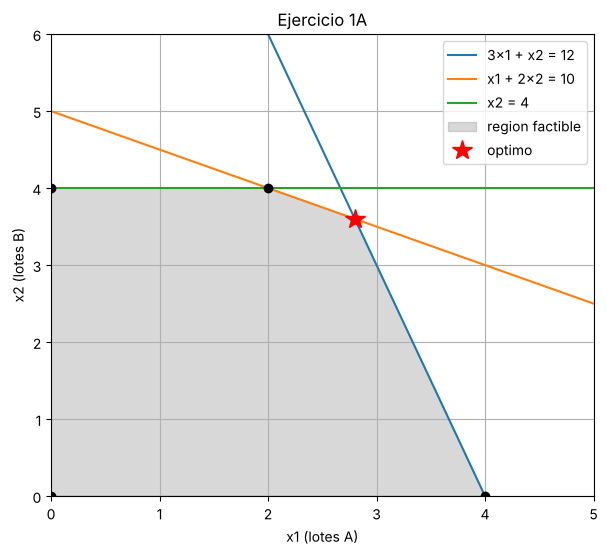

In [ ]:
x = np.linspace(0, 5, 100)

plt.figure(figsize=(7, 6))
plt.plot(x, 12 - 3*x, label="3x1 + x2 = 12")
plt.plot(x, (10 - x)/2, label="x1 + 2x2 = 10")
plt.plot(x, 4 + 0*x, label="x2 = 4")

# vertices de la region (los vi en la grafica)
vx = [0, 4, 2.8, 2, 0]
vy = [0, 0, 3.6, 4, 4]
plt.fill(vx, vy, color="gray", alpha=0.3, label="region factible")
plt.plot(vx, vy, "ko")

plt.plot(x1, x2, "r*", markersize=15, label="optimo")

plt.xlim(0, 5)
plt.ylim(0, 6)
plt.xlabel("x1 (lotes A)")
plt.ylabel("x2 (lotes B)")
plt.title("Ejercicio 1A")
plt.legend()
plt.grid()
plt.show()

Evalúo $z$ en los vértices para ver que el mejor sea el mismo que dio linprog:

In [ ]:
for i in range(5):
    zv = 9*vx[i] + 6*vy[i]
    print("vertice (", vx[i], ",", vy[i], ")   z =", round(zv, 2))

vertice ( 0 , 0 )   z = 0
vertice ( 4 , 0 )   z = 36
vertice ( 2.8 , 3.6 )   z = 46.8
vertice ( 2 , 4 )   z = 42
vertice ( 0 , 4 )   z = 24


**Interpretación:** conviene procesar 2.8 lotes A y 3.6 lotes B, con una utilidad de 46.8. En ese punto se acaban el cómputo y la memoria (holgura 0). La condición de máximo 4 lotes B no está activa (sobran 0.4). El óptimo está en el vértice donde se cruzan las rectas de cómputo y memoria.

---
## Ejercicio 2A. Soluciones básicas factibles y simplex primal

$$\max\ z = 4x_1 + 3x_2$$
$$x_1 + x_2 \le 5$$
$$2x_1 + x_2 \le 8$$
$$x_1, x_2 \ge 0$$

In [ ]:
res2 = linprog([-4, -3], A_ub=[[1, 1], [2, 1]], b_ub=[5, 8], bounds=[(0, None), (0, None)])

x1 = res2.x[0]
x2 = res2.x[1]
print("x1* =", round(x1, 4))
print("x2* =", round(x2, 4))
print("z*  =", round(-res2.fun, 4))

s1 = 5 - (x1 + x2)
s2 = 8 - (2*x1 + x2)
print("holgura s1 =", round(s1, 4))
print("holgura s2 =", round(s2, 4))

x1* = 3.0
x2* = 2.0
z*  = 18.0
holgura s1 = 0.0
holgura s2 = 0.0


**Comprobación con tableau** (convención de clase $z - c^Tx = 0$: si hay un negativo en la fila z todavía se puede mejorar).

Forma estándar:
$$x_1 + x_2 + s_1 = 5$$
$$2x_1 + x_2 + s_2 = 8$$
$$z - 4x_1 - 3x_2 = 0$$

In [ ]:
# columnas:   x1   x2   s1   s2   RHS
fila1 = [1, 1, 1, 0, 5]
fila2 = [2, 1, 0, 1, 8]
filaz = [-4, -3, 0, 0, 0]
base = ["s1", "s2"]

def mostrar(fila1, fila2, filaz, base):
    print("        x1, x2, s1, s2, RHS")
    print(base[0], " ", fila1)
    print(base[1], " ", fila2)
    print("z   ", filaz)

print("Tableau inicial")
mostrar(fila1, fila2, filaz, base)
print("SBF inicial: x1 = 0, x2 = 0, s1 = 5, s2 = 8, z = 0")

Tableau inicial
        x1, x2, s1, s2, RHS
s1   [1, 1, 1, 0, 5]
s2   [2, 1, 0, 1, 8]
z    [-4, -3, 0, 0, 0]
SBF inicial: x1 = 0, x2 = 0, s1 = 5, s2 = 8, z = 0


**Iteración 1**
- En la fila z el más negativo es $-4$ → **entra $x_1$**
- Razones: $5/1 = 5$, $8/2 = 4$ → la mínima es 4 → **sale $s_2$**
- Pivote = 2

In [ ]:
print("razones:", fila1[4] / fila1[0], fila2[4] / fila2[0])

# fila pivote: fila2 entre 2
piv = fila2[0]
for j in range(5):
    fila2[j] = fila2[j] / piv

# fila1 = fila1 - 1 * fila2
k = fila1[0]
for j in range(5):
    fila1[j] = fila1[j] - k * fila2[j]

# filaz = filaz + 4 * fila2
k = filaz[0]
for j in range(5):
    filaz[j] = filaz[j] - k * fila2[j]

base[1] = "x1"
mostrar(fila1, fila2, filaz, base)
print("SBF: x1 =", fila2[4], ", s1 =", fila1[4], ", x2 = 0, s2 = 0, z =", filaz[4])

razones: 5.0 4.0
        x1, x2, s1, s2, RHS
s1   [0.0, 0.5, 1.0, -0.5, 1.0]
x1   [1.0, 0.5, 0.0, 0.5, 4.0]
z    [0.0, -1.0, 0.0, 2.0, 16.0]
SBF: x1 = 4.0 , s1 = 1.0 , x2 = 0, s2 = 0, z = 16.0


**Iteración 2**
- En la fila z queda $-1$ en $x_2$ → **entra $x_2$**
- Razones: $1/0.5 = 2$, $4/0.5 = 8$ → mínima 2 → **sale $s_1$**
- Pivote = 0.5

In [ ]:
print("razones:", fila1[4] / fila1[1], fila2[4] / fila2[1])

piv = fila1[1]
for j in range(5):
    fila1[j] = fila1[j] / piv

k = fila2[1]
for j in range(5):
    fila2[j] = fila2[j] - k * fila1[j]

k = filaz[1]
for j in range(5):
    filaz[j] = filaz[j] - k * fila1[j]

base[0] = "x2"
mostrar(fila1, fila2, filaz, base)
print("SBF: x1 =", fila2[4], ", x2 =", fila1[4], ", s1 = 0, s2 = 0, z =", filaz[4])

razones: 2.0 8.0
        x1, x2, s1, s2, RHS
x2   [0.0, 1.0, 2.0, -1.0, 2.0]
x1   [1.0, 0.0, -1.0, 1.0, 3.0]
z    [0.0, 0.0, 2.0, 1.0, 18.0]
SBF: x1 = 3.0 , x2 = 2.0 , s1 = 0, s2 = 0, z = 18.0


Ya no hay negativos en la fila z → es óptimo.

**Interpretación:** el óptimo es $x_1^* = 3$, $x_2^* = 2$ con $z^* = 18$. Las dos holguras son 0, entonces las dos restricciones se usan completas. El tableau y linprog dan lo mismo.

---
## Ejercicio 3A. Dualidad

Primal:
$$\max\ 5x_1 + 4x_2$$
$$2x_1 + x_2 \le 8$$
$$x_1 + 2x_2 \le 8$$
$$x \ge 0$$

**A, b y c:**
$$A = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix},\quad b = \begin{pmatrix} 8 \\ 8 \end{pmatrix},\quad c = \begin{pmatrix} 5 \\ 4 \end{pmatrix}$$

**Dual canónico** (el primal es max con $\le$, entonces el dual es min con $\ge$ y se usa $A^T$):
$$\min\ w = 8y_1 + 8y_2$$
$$2y_1 + y_2 \ge 5$$
$$y_1 + 2y_2 \ge 4$$
$$y \ge 0$$

In [ ]:
A = [[2, 1],
     [1, 2]]
b = [8, 8]
c = [5, 4]

# transpuesta a mano
At = [[A[0][0], A[1][0]],
      [A[0][1], A[1][1]]]
print("A^T =", At)

A^T = [[2, 1], [1, 2]]


In [ ]:
# primal
resP = linprog([-5, -4], A_ub=A, b_ub=b, bounds=[(0, None), (0, None)])
x1 = resP.x[0]
x2 = resP.x[1]
zP = -resP.fun
print("PRIMAL: x1 =", round(x1, 4), "  x2 =", round(x2, 4), "  z* =", round(zP, 4))

# dual: linprog solo acepta <=, entonces multiplico por -1 las de >=
resD = linprog([8, 8], A_ub=[[-2, -1], [-1, -2]], b_ub=[-5, -4], bounds=[(0, None), (0, None)])
y1 = resD.x[0]
y2 = resD.x[1]
wD = resD.fun
print("DUAL:   y1 =", round(y1, 4), "  y2 =", round(y2, 4), "  w* =", round(wD, 4))

PRIMAL: x1 = 2.6667   x2 = 2.6667   z* = 24.0
DUAL:   y1 = 2.0   y2 = 1.0   w* = 24.0


**Verificación de factibilidad y valores:**

In [ ]:
print("Primal:")
print("  2x1 + x2 =", round(2*x1 + x2, 4), "<= 8")
print("  x1 + 2x2 =", round(x1 + 2*x2, 4), "<= 8")
print("  x1, x2 >= 0:", x1 >= 0 and x2 >= 0)

print("Dual:")
print("  2y1 + y2 =", round(2*y1 + y2, 4), ">= 5")
print("  y1 + 2y2 =", round(y1 + 2*y2, 4), ">= 4")
print("  y1, y2 >= 0:", y1 >= 0 and y2 >= 0)

print()
print("z primal = 5x1 + 4x2 =", round(5*x1 + 4*x2, 4))
print("w dual   = 8y1 + 8y2 =", round(8*y1 + 8*y2, 4))

Primal:
  2x1 + x2 = 8.0 <= 8
  x1 + 2x2 = 8.0 <= 8
  x1, x2 >= 0: True
Dual:
  2y1 + y2 = 5.0 >= 5
  y1 + 2y2 = 4.0 >= 4
  y1, y2 >= 0: True

z primal = 5x1 + 4x2 = 24.0
w dual   = 8y1 + 8y2 = 24.0


**Interpretación:** el primal da $x^* = (8/3, 8/3)$ con $z^* = 24$ y el dual da $y^* = (2, 1)$ con $w^* = 24$. Por dualidad débil cualquier factible del primal cumple $z \le w$ para cualquier factible del dual. Aquí los dos son factibles y dan el mismo valor, entonces eso es el certificado de que los dos son óptimos. $y_1 = 2$ significa que una unidad más del primer recurso sube el objetivo 2, y $y_2 = 1$ lo mismo para el segundo.

---
## Ejercicio 4A. Simplex dual

Tableau que nos dan (básicas $x_1$, $x_2$):

| Fila | x₁ | x₂ | s₁ | s₂ | RHS |
|---|---|---|---|---|---|
| x₁ | 1 | 0 | −1 | 1 | 7 |
| x₂ | 0 | 1 | 2 | −1 | −6 |
| z | 0 | 0 | 2 | 1 | 10 |

**Reconstrucción del PL modificado**

Al inicio las columnas de $s_1$ y $s_2$ eran la identidad, entonces lo que quedó debajo de $s_1, s_2$ es $B^{-1}$:
$$B^{-1} = \begin{pmatrix} -1 & 1 \\ 2 & -1 \end{pmatrix}$$

- $B$ (columnas originales de $x_1, x_2$) es la inversa de $B^{-1}$.
- El RHS original es $b = B \cdot (7, -6)$.
- En la fila z, lo que está bajo las holguras son las duales $y = (2, 1)$, y como $y^T = c_B^T B^{-1}$, entonces $c_B^T = y^T B$.

In [ ]:
# B^-1 del tableau
a, bb = -1, 1
cc, d = 2, -1

# inversa de 2x2: 1/det * [[d, -b], [-c, a]]
det = a*d - bb*cc
B = [[d/det, -bb/det],
     [-cc/det, a/det]]
print("det =", det)
print("B =", B)

# b = B * (7, -6)
b1 = B[0][0]*7 + B[0][1]*(-6)
b2 = B[1][0]*7 + B[1][1]*(-6)
print("b original = (", b1, ",", b2, ")")

# c = y * B  con y = (2, 1)
c1 = 2*B[0][0] + 1*B[1][0]
c2 = 2*B[0][1] + 1*B[1][1]
print("c original = (", c1, ",", c2, ")")

print("comprobacion: z = c1*7 + c2*(-6) =", c1*7 + c2*(-6), "(debe dar 10)")

det = -1
B = [[1.0, 1.0], [2.0, 1.0]]
b original = ( 1.0 , 8.0 )
c original = ( 4.0 , 3.0 )
comprobacion: z = c1*7 + c2*(-6) = 10.0 (debe dar 10)


Sale el PL modificado:
$$\max\ z = 4x_1 + 3x_2$$
$$x_1 + x_2 \le 1$$
$$2x_1 + x_2 \le 8$$
$$x \ge 0$$

Es el mismo del ejercicio 2 pero con el lado derecho de la primera restricción en 1 en vez de 5.

In [ ]:
res4 = linprog([-4, -3], A_ub=[[1, 1], [2, 1]], b_ub=[1, 8], bounds=[(0, None), (0, None)])
x1 = res4.x[0]
x2 = res4.x[1]
print("x1* =", round(x1, 4), "  x2* =", round(x2, 4), "  z* =", round(-res4.fun, 4))
print("x1 + x2 =", round(x1 + x2, 4), "<= 1    s1 =", round(1 - x1 - x2, 4))
print("2x1 + x2 =", round(2*x1 + x2, 4), "<= 8    s2 =", round(8 - 2*x1 - x2, 4))

x1* = 1.0   x2* = 0.0   z* = 4.0
x1 + x2 = 1.0 <= 1    s1 = 0.0
2x1 + x2 = 2.0 <= 8    s2 = 6.0


**Comprobación con el simplex dual sobre el tableau**

Aquí no se usa simplex primal porque la fila z ya no tiene negativos (ya es dual-factible, "óptimo"), pero el RHS de $x_2$ es $-6$, entonces la solución no es factible. El simplex dual arregla eso:
- **Sale** la fila con RHS negativo → $x_2$ ($-6$)
- **Entra** la columna con coeficiente negativo en esa fila y menor $|z_j / a_{rj}|$:
  - $s_1$: coeficiente 2 (positivo, no se puede)
  - $s_2$: coeficiente $-1$ → $|1 / -1| = 1$

  → **entra $s_2$**, pivote $= -1$

In [ ]:
# columnas:   x1   x2   s1   s2   RHS
fila1 = [1, 0, -1, 1, 7]
fila2 = [0, 1, 2, -1, -6]
filaz = [0, 0, 2, 1, 10]
base = ["x1", "x2"]

print("Tableau inicial")
mostrar(fila1, fila2, filaz, base)

# fila pivote: fila2 entre -1
piv = fila2[3]
for j in range(5):
    fila2[j] = fila2[j] / piv

# fila1 = fila1 - 1 * fila2
k = fila1[3]
for j in range(5):
    fila1[j] = fila1[j] - k * fila2[j]

# filaz = filaz - 1 * fila2
k = filaz[3]
for j in range(5):
    filaz[j] = filaz[j] - k * fila2[j]

base[1] = "s2"
print()
print("Despues del pivote")
mostrar(fila1, fila2, filaz, base)

Tableau inicial
        x1, x2, s1, s2, RHS
x1   [1, 0, -1, 1, 7]
x2   [0, 1, 2, -1, -6]
z    [0, 0, 2, 1, 10]

Despues del pivote
        x1, x2, s1, s2, RHS
x1   [1.0, 1.0, 1.0, 0.0, 1.0]
s2   [-0.0, -1.0, -2.0, 1.0, 6.0]
z    [0.0, 1.0, 4.0, 0.0, 4.0]


Ahora todos los RHS son $\ge 0$ y la fila z no tiene negativos → óptimo.

**Interpretación:** el óptimo del PL modificado es $x_1^* = 1$, $x_2^* = 0$, $z^* = 4$, con $s_2 = 6$ (sobran 6 unidades del segundo recurso). Con un solo pivote del simplex dual (entra $s_2$, sale $x_2$) se llega a lo mismo que linprog.

---
## Ejercicio 5A. Análisis de sensibilidad

$$\max\ 4x_1 + 3x_2$$
$$x_1 + x_2 \le 5 + \Delta$$
$$2x_1 + x_2 \le 8$$
$$x \ge 0$$

Primero con $\Delta = 0$ para tener la base de referencia.

In [ ]:
res5 = linprog([-4, -3], A_ub=[[1, 1], [2, 1]], b_ub=[5, 8], bounds=[(0, None), (0, None)])
print("Delta = 0:  x1 =", round(res5.x[0], 4), "  x2 =", round(res5.x[1], 4), "  z =", round(-res5.fun, 4))
print("las dos holguras son 0, entonces la base es {x1, x2}")

Delta = 0:  x1 = 3.0   x2 = 2.0   z = 18.0
las dos holguras son 0, entonces la base es {x1, x2}


Con la base $\{x_1, x_2\}$:
$$B = \begin{pmatrix} 1 & 1 \\ 2 & 1 \end{pmatrix}$$
y $x_B = B^{-1} b(\Delta)$ con $b(\Delta) = (5 + \Delta,\ 8)$.

In [ ]:
# inversa de B a mano
det = 1*1 - 1*2
Binv = [[1/det, -1/det],
        [-2/det, 1/det]]
print("det =", det)
print("B^-1 =", Binv)

# x_B = B^-1 * (5 + delta, 8)
# separo la parte que no depende de delta y la que si
x1_fijo = Binv[0][0]*5 + Binv[0][1]*8
x1_delta = Binv[0][0]
x2_fijo = Binv[1][0]*5 + Binv[1][1]*8
x2_delta = Binv[1][0]

print("x1 =", x1_fijo, "+", x1_delta, "* delta")
print("x2 =", x2_fijo, "+", x2_delta, "* delta")

det = -1
B^-1 = [[-1.0, 1.0], [2.0, -1.0]]
x1 = 3.0 + -1.0 * delta
x2 = 2.0 + 2.0 * delta


Para que la base siga siendo factible:
$$x_1 = 3 - \Delta \ge 0 \Rightarrow \Delta \le 3$$
$$x_2 = 2 + 2\Delta \ge 0 \Rightarrow \Delta \ge -1$$

Entonces $-1 \le \Delta \le 3$ y ahí:
$$z^*(\Delta) = 4(3 - \Delta) + 3(2 + 2\Delta) = 18 + 2\Delta$$

Lo pruebo con linprog para valores dentro y fuera del intervalo:

In [ ]:
deltas = [-2, -1, -0.5, 0, 1, 2, 3, 4, 5]

for d in deltas:
    r = linprog([-4, -3], A_ub=[[1, 1], [2, 1]], b_ub=[5 + d, 8], bounds=[(0, None), (0, None)])
    z_lp = -r.fun
    z_formula = 18 + 2*d
    if d >= -1 and d <= 3:
        donde = "dentro"
    else:
        donde = "FUERA"
    print("delta =", d, " x1 =", round(r.x[0], 2), " x2 =", round(r.x[1], 2), " z linprog =", round(z_lp, 2), " formula =", z_formula, " ", donde)

delta = -2  x1 = 3.0  x2 = 0.0  z linprog = 12.0  formula = 14   FUERA
delta = -1  x1 = 4.0  x2 = -0.0  z linprog = 16.0  formula = 16   dentro
delta = -0.5  x1 = 3.5  x2 = 1.0  z linprog = 17.0  formula = 17.0   dentro
delta = 0  x1 = 3.0  x2 = 2.0  z linprog = 18.0  formula = 18   dentro
delta = 1  x1 = 2.0  x2 = 4.0  z linprog = 20.0  formula = 20   dentro
delta = 2  x1 = 1.0  x2 = 6.0  z linprog = 22.0  formula = 22   dentro
delta = 3  x1 = 0.0  x2 = 8.0  z linprog = 24.0  formula = 24   dentro
delta = 4  x1 = 0.0  x2 = 8.0  z linprog = 24.0  formula = 26   FUERA
delta = 5  x1 = 0.0  x2 = 8.0  z linprog = 24.0  formula = 28   FUERA


**Interpretación:** mientras $-1 \le \Delta \le 3$ la base $\{x_1, x_2\}$ sigue siendo óptima y cada unidad extra del primer recurso sube $z$ en 2. Ese 2 es el precio sombra del primer recurso (el que queda abajo de $s_1$ en la fila z del tableau final del ejercicio 2). Fuera del intervalo la fórmula ya no sirve: con $\Delta = 4$ la fórmula daría 26 pero linprog da 24, y con $\Delta = -2$ daría 14 pero sale 12, porque cambió la base.

---
## Ejercicio 6A. Problema de transporte

| | D1 | D2 | D3 | Oferta |
|---|---|---|---|---|
| O1 | 9 | 8 | 9 | 18 |
| O2 | 8 | 3 | 7 | 27 |
| Demanda | 10 | 15 | 20 | |

**Balance:** oferta = 18 + 27 = 45, demanda = 10 + 15 + 20 = 45 → está balanceado.

**Modelo:** $x_{ij}$ = unidades que van de $O_i$ a $D_j$
$$\min\ z = 9x_{11} + 8x_{12} + 9x_{13} + 8x_{21} + 3x_{22} + 7x_{23}$$
$$x_{11} + x_{12} + x_{13} = 18 \qquad x_{21} + x_{22} + x_{23} = 27$$
$$x_{11} + x_{21} = 10 \qquad x_{12} + x_{22} = 15 \qquad x_{13} + x_{23} = 20$$
$$x_{ij} \ge 0$$

In [ ]:
C = [[9, 8, 9],
     [8, 3, 7]]
oferta = [18, 27]
demanda = [10, 15, 20]

print("oferta total =", oferta[0] + oferta[1])
print("demanda total =", demanda[0] + demanda[1] + demanda[2])

# orden de variables: x11, x12, x13, x21, x22, x23
c = [9, 8, 9, 8, 3, 7]

A_eq = [[1, 1, 1, 0, 0, 0],   # O1
        [0, 0, 0, 1, 1, 1],   # O2
        [1, 0, 0, 1, 0, 0],   # D1
        [0, 1, 0, 0, 1, 0],   # D2
        [0, 0, 1, 0, 0, 1]]   # D3
b_eq = [18, 27, 10, 15, 20]

res6 = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=[(0, None)]*6)

x = res6.x
X = [[float(x[0]), float(x[1]), float(x[2])],
     [float(x[3]), float(x[4]), float(x[5])]]

print()
print("Plan optimo:")
print("      D1, D2, D3")
print("O1", X[0])
print("O2", X[1])
print("Costo minimo =", res6.fun)

oferta total = 45
demanda total = 45

Plan optimo:
      D1, D2, D3
O1 [10.0, 0.0, 8.0]
O2 [0.0, 15.0, 12.0]
Costo minimo = 291.0


**Verificación de ofertas y demandas:**

In [ ]:
print("O1 manda:", X[0][0] + X[0][1] + X[0][2], "  oferta =", oferta[0])
print("O2 manda:", X[1][0] + X[1][1] + X[1][2], "  oferta =", oferta[1])
print("D1 recibe:", X[0][0] + X[1][0], "  demanda =", demanda[0])
print("D2 recibe:", X[0][1] + X[1][1], "  demanda =", demanda[1])
print("D3 recibe:", X[0][2] + X[1][2], "  demanda =", demanda[2])

costo = 0
for i in range(2):
    for j in range(3):
        costo = costo + C[i][j] * X[i][j]
print("costo calculado a mano =", costo)

O1 manda: 18.0   oferta = 18
O2 manda: 27.0   oferta = 27
D1 recibe: 10.0   demanda = 10
D2 recibe: 15.0   demanda = 15
D3 recibe: 20.0   demanda = 20
costo calculado a mano = 291.0


Para la segunda versión se arranca con esquina noroeste, entonces la saco para ver cuánto hay que mejorar:

In [ ]:
of = [18, 27]
de = [10, 15, 20]
NO = [[0, 0, 0],
      [0, 0, 0]]
i = 0
j = 0
while i < 2 and j < 3:
    q = min(of[i], de[j])
    NO[i][j] = q
    of[i] = of[i] - q
    de[j] = de[j] - q
    print("celda (O" + str(i+1) + ", D" + str(j+1) + ") =", q)
    if of[i] == 0:
        i = i + 1
    else:
        j = j + 1

print()
print("Esquina noroeste:")
print("O1", NO[0])
print("O2", NO[1])

costo_no = 0
for i in range(2):
    for j in range(3):
        costo_no = costo_no + C[i][j] * NO[i][j]
print("costo esquina noroeste =", costo_no)

celda (O1, D1) = 10
celda (O1, D2) = 8
celda (O2, D2) = 7
celda (O2, D3) = 20

Esquina noroeste:
O1 [10, 8, 0]
O2 [0, 7, 20]
costo esquina noroeste = 315


**Interpretación:** el plan óptimo manda de O1: 10 a D1 y 8 a D3; de O2: 15 a D2 y 12 a D3, con costo mínimo 291. Se cumplen todas las ofertas y demandas. La esquina noroeste empieza en 315, entonces con potenciales y costos reducidos hay que bajar 24. Tiene sentido que O2 surta toda la D2 porque ahí cuesta 3, lo más barato de la tabla.

---
## Ejercicio 7A. Asignación (método húngaro)

| | T1 | T2 | T3 | T4 |
|---|---|---|---|---|
| A1 | 4 | 9 | 14 | 3 |
| A2 | 4 | 8 | 12 | 3 |
| A3 | 9 | 10 | 9 | 7 |
| A4 | 10 | 19 | 10 | 13 |

Cada agente hace una sola tarea y cada tarea la hace un solo agente. Minimizar costo.

In [ ]:
C = [[4, 9, 14, 3],
     [4, 8, 12, 3],
     [9, 10, 9, 7],
     [10, 19, 10, 13]]

filas, cols = linear_sum_assignment(C)

total = 0
for k in range(4):
    i = filas[k]
    j = cols[k]
    print("A" + str(i+1), "-> T" + str(j+1), "   costo =", C[i][j])
    total = total + C[i][j]
print("Costo total =", total)

A1 -> T4    costo = 3
A2 -> T1    costo = 4
A3 -> T2    costo = 10
A4 -> T3    costo = 10
Costo total = 27


**Verificación de que cada fila y columna se usa una sola vez:**

In [ ]:
X = [[0, 0, 0, 0],
     [0, 0, 0, 0],
     [0, 0, 0, 0],
     [0, 0, 0, 0]]
for k in range(4):
    X[filas[k]][cols[k]] = 1

print("Matriz de asignacion:")
for fila in X:
    print(fila)

print()
for i in range(4):
    print("fila A" + str(i+1), "suma =", X[i][0] + X[i][1] + X[i][2] + X[i][3])
for j in range(4):
    print("columna T" + str(j+1), "suma =", X[0][j] + X[1][j] + X[2][j] + X[3][j])

Matriz de asignacion:
[0, 0, 0, 1]
[1, 0, 0, 0]
[0, 1, 0, 0]
[0, 0, 1, 0]

fila A1 suma = 1
fila A2 suma = 1
fila A3 suma = 1
fila A4 suma = 1
columna T1 suma = 1
columna T2 suma = 1
columna T3 suma = 1
columna T4 suma = 1


Hago también la reducción por filas y por columnas (primer paso del húngaro), para la segunda versión:

In [ ]:
R = [fila.copy() for fila in C]

# reduccion por filas
for i in range(4):
    m = min(R[i])
    for j in range(4):
        R[i][j] = R[i][j] - m
    print("fila A" + str(i+1), ": minimo =", m)

print("Despues de reducir filas:")
for fila in R:
    print(fila)

# reduccion por columnas
print()
for j in range(4):
    m = min(R[0][j], R[1][j], R[2][j], R[3][j])
    for i in range(4):
        R[i][j] = R[i][j] - m
    print("columna T" + str(j+1), ": minimo =", m)

print("Despues de reducir columnas:")
for fila in R:
    print(fila)

fila A1 : minimo = 3
fila A2 : minimo = 3
fila A3 : minimo = 7
fila A4 : minimo = 10
Despues de reducir filas:
[1, 6, 11, 0]
[1, 5, 9, 0]
[2, 3, 2, 0]
[0, 9, 0, 3]

columna T1 : minimo = 0
columna T2 : minimo = 3
columna T3 : minimo = 0
columna T4 : minimo = 0
Despues de reducir columnas:
[1, 3, 11, 0]
[1, 2, 9, 0]
[2, 0, 2, 0]
[0, 6, 0, 3]


**Interpretación:** la asignación óptima es A1→T4, A2→T1, A3→T2, A4→T3 con costo 3 + 4 + 10 + 10 = 27. Cada agente y cada tarea aparece una sola vez. Después de reducir, A1 y A2 solo tienen cero en la columna T4, entonces no se pueden escoger 4 ceros independientes y a mano hace falta por lo menos un ajuste.

---
## Ejercicio 8A. Flujo de costo mínimo

Red de la figura de la guía ($u$ = capacidad, $c$ = costo):

| Arco | u | c |
|---|---|---|
| S→A | 4 | 2 |
| S→B | 4 | 5 |
| A→B | 2 | 1 |
| A→T | 3 | 4 |
| B→T | 5 | 2 |

Hay que mandar exactamente 6 unidades de S a T. Convención: salidas − entradas $= b_i$ con $b_S = 6$, $b_A = 0$, $b_B = 0$, $b_T = -6$.

**Modelo:**
$$\min\ 2x_{SA} + 5x_{SB} + x_{AB} + 4x_{AT} + 2x_{BT}$$
$$S:\ x_{SA} + x_{SB} = 6$$
$$A:\ x_{AB} + x_{AT} - x_{SA} = 0$$
$$B:\ x_{BT} - x_{SB} - x_{AB} = 0$$
$$T:\ -x_{AT} - x_{BT} = -6$$
$$0 \le x_{ij} \le u_{ij}$$

In [ ]:
# orden: SA, SB, AB, AT, BT
costo = [2, 5, 1, 4, 2]
cap = [4, 4, 2, 3, 5]

#         SA  SB  AB  AT  BT
A_eq = [[ 1,  1,  0,  0,  0],   # S
        [-1,  0,  1,  1,  0],   # A
        [ 0, -1, -1,  0,  1],   # B
        [ 0,  0,  0, -1, -1]]   # T
b_eq = [6, 0, 0, -6]

limites = [(0, 4), (0, 4), (0, 2), (0, 3), (0, 5)]

res8 = linprog(costo, A_eq=A_eq, b_eq=b_eq, bounds=limites)

xSA, xSB, xAB, xAT, xBT = res8.x
print("xSA =", xSA)
print("xSB =", xSB)
print("xAB =", xAB)
print("xAT =", xAT)
print("xBT =", xBT)
print("Costo minimo =", res8.fun)

xSA = 4.0
xSB = 2.0
xAB = 2.0
xAT = 2.0
xBT = 4.0
Costo minimo = 36.0


**Verificación de conservación y capacidades:**

> Agregar bloque entrecomillado



In [ ]:
print("S: salidas - entradas =", xSA + xSB, "  (debe ser 6)")
print("A: salidas - entradas =", xAB + xAT - xSA, "  (debe ser 0)")
print("B: salidas - entradas =", xBT - xSB - xAB, "  (debe ser 0)")
print("T: salidas - entradas =", -xAT - xBT, "  (debe ser -6)")
print()
print("SA:", xSA, "<= 4")
print("SB:", xSB, "<= 4")
print("AB:", xAB, "<= 2")
print("AT:", xAT, "<= 3")
print("BT:", xBT, "<= 5")

S: salidas - entradas = 6.0   (debe ser 6)
A: salidas - entradas = 0.0   (debe ser 0)
B: salidas - entradas = 0.0   (debe ser 0)
T: salidas - entradas = -6.0   (debe ser -6)

SA: 4.0 <= 4
SB: 2.0 <= 4
AB: 2.0 <= 2
AT: 2.0 <= 3
BT: 4.0 <= 5


Comparo con el flujo inicial que da la guía para la segunda versión ($x_{SA}=3, x_{SB}=3, x_{AB}=0, x_{AT}=3, x_{BT}=3$):

In [ ]:
c_inicial = 2*3 + 5*3 + 1*0 + 4*3 + 2*3
print("costo flujo inicial =", c_inicial)
print("costo optimo        =", res8.fun)
print("diferencia          =", c_inicial - res8.fun)

costo flujo inicial = 39
costo optimo        = 36.0
diferencia          = 3.0


**Interpretación:** el flujo óptimo es $x_{SA} = 4$, $x_{SB} = 2$, $x_{AB} = 2$, $x_{AT} = 2$, $x_{BT} = 4$ con costo 36. Se cumple la conservación en todos los nodos y ninguna capacidad se pasa.

Tiene sentido por los caminos:
- S→A→B→T cuesta 2+1+2 = 5, el más barato, y se llena A→B (2 unidades).
- S→A→T cuesta 6 y se usa hasta que S→A se llena (4).
- Lo que falta (2) se va por S→B→T, que cuesta 7.

El flujo inicial de la guía cuesta 39, entonces el simplex general tiene que bajar 3.

---
## Ejercicio 9A. Flujo máximo

Red de la figura de la guía (etiquetas = capacidades):

| Arco | capacidad |
|---|---|
| s→a | 3 |
| s→b | 2 |
| a→b | 2 |
| a→t | 2 |
| b→t | 3 |

In [ ]:
G = nx.DiGraph()
G.add_edge("s", "a", capacity=3)
G.add_edge("s", "b", capacity=2)
G.add_edge("a", "b", capacity=2)
G.add_edge("a", "t", capacity=2)
G.add_edge("b", "t", capacity=3)

valor, flujo = nx.maximum_flow(G, "s", "t")
print("Flujo maximo =", valor)
print()
print("s -> a :", flujo["s"]["a"], "de 3")
print("s -> b :", flujo["s"]["b"], "de 2")
print("a -> b :", flujo["a"]["b"], "de 2")
print("a -> t :", flujo["a"]["t"], "de 2")
print("b -> t :", flujo["b"]["t"], "de 3")

Flujo maximo = 5

s -> a : 3 de 3
s -> b : 2 de 2
a -> b : 1 de 2
a -> t : 2 de 2
b -> t : 3 de 3


**Verificación de conservación en a y b:**

In [ ]:
entra_a = flujo["s"]["a"]
sale_a = flujo["a"]["b"] + flujo["a"]["t"]
print("nodo a: entra", entra_a, "  sale", sale_a)

entra_b = flujo["s"]["b"] + flujo["a"]["b"]
sale_b = flujo["b"]["t"]
print("nodo b: entra", entra_b, "  sale", sale_b)

nodo a: entra 3   sale 3
nodo b: entra 3   sale 3


**Caminos aumentantes** (para la segunda versión empiezo con s→a→b→t).

Guardo las capacidades residuales en un diccionario. Cuando mando flujo por $u \to v$ resto en $u \to v$ y sumo en el arco inverso $v \to u$.

In [ ]:
r = {}
r["s", "a"] = 3
r["s", "b"] = 2
r["a", "b"] = 2
r["a", "t"] = 2
r["b", "t"] = 3
# arcos inversos empiezan en 0
r["a", "s"] = 0
r["b", "s"] = 0
r["b", "a"] = 0
r["t", "a"] = 0
r["t", "b"] = 0
total = 0

**Camino 1:** s→a→b→t

In [ ]:
cuello = min(r["s", "a"], r["a", "b"], r["b", "t"])
print("cuello de botella = min(", r["s", "a"], ",", r["a", "b"], ",", r["b", "t"], ") =", cuello)

r["s", "a"] -= cuello; r["a", "s"] += cuello
r["a", "b"] -= cuello; r["b", "a"] += cuello
r["b", "t"] -= cuello; r["t", "b"] += cuello
total = total + cuello

print("residuales: s->a =", r["s", "a"], ", a->b =", r["a", "b"], ", b->t =", r["b", "t"], ", inverso b->a =", r["b", "a"])
print("flujo acumulado =", total)

cuello de botella = min( 3 , 2 , 3 ) = 2
residuales: s->a = 1 , a->b = 0 , b->t = 1 , inverso b->a = 2
flujo acumulado = 2


**Camino 2:** s→a→t

In [ ]:
cuello = min(r["s", "a"], r["a", "t"])
print("cuello de botella = min(", r["s", "a"], ",", r["a", "t"], ") =", cuello)

r["s", "a"] -= cuello; r["a", "s"] += cuello
r["a", "t"] -= cuello; r["t", "a"] += cuello
total = total + cuello

print("residuales: s->a =", r["s", "a"], ", a->t =", r["a", "t"])
print("flujo acumulado =", total)

cuello de botella = min( 1 , 2 ) = 1
residuales: s->a = 0 , a->t = 1
flujo acumulado = 3


**Camino 3:** s→b→t

In [ ]:
cuello = min(r["s", "b"], r["b", "t"])
print("cuello de botella = min(", r["s", "b"], ",", r["b", "t"], ") =", cuello)

r["s", "b"] -= cuello; r["b", "s"] += cuello
r["b", "t"] -= cuello; r["t", "b"] += cuello
total = total + cuello

print("residuales: s->b =", r["s", "b"], ", b->t =", r["b", "t"])
print("flujo acumulado =", total)

cuello de botella = min( 2 , 1 ) = 1
residuales: s->b = 1 , b->t = 0
flujo acumulado = 4


**Camino 4:** s→b→a→t

b→t ya está lleno, pero en la red residual existe el arco inverso b→a (porque en el camino 1 mandamos 2 por a→b). Usarlo significa "regresar" flujo de a→b para que mejor se vaya por a→t, que todavía tiene 1 libre.

In [ ]:
cuello = min(r["s", "b"], r["b", "a"], r["a", "t"])
print("cuello de botella = min(", r["s", "b"], ",", r["b", "a"], ",", r["a", "t"], ") =", cuello)

r["s", "b"] -= cuello; r["b", "s"] += cuello
r["b", "a"] -= cuello; r["a", "b"] += cuello   # arco inverso
r["a", "t"] -= cuello; r["t", "a"] += cuello
total = total + cuello

print("residuales: s->b =", r["s", "b"], ", b->a =", r["b", "a"], ", a->t =", r["a", "t"])
print("flujo acumulado =", total)

cuello de botella = min( 1 , 2 , 1 ) = 1
residuales: s->b = 0 , b->a = 1 , a->t = 0
flujo acumulado = 5


Ya no hay camino de s a t: s→a y s→b tienen residual 0.

**Cota:** el corte $\{s\} \mid \{a, b, t\}$ tiene capacidad $3 + 2 = 5$.

In [ ]:
corte = 3 + 2
print("residual s->a =", r["s", "a"], ",  residual s->b =", r["s", "b"])
print("capacidad del corte {s} =", corte)
print("flujo maximo (caminos) =", total)
print("flujo maximo (networkx) =", valor)

residual s->a = 0 ,  residual s->b = 0
capacidad del corte {s} = 5
flujo maximo (caminos) = 5
flujo maximo (networkx) = 5


**Interpretación:** el flujo máximo es 5. Después de s→a→b→t (2), s→a→t (1) y s→b→t (1), todavía se pudo mandar 1 más por s→b→a→t usando el arco inverso b→a. Al final los dos arcos que salen de s (3 + 2 = 5) quedan llenos, entonces el corte $\{s\}$ vale 5 igual que el flujo y eso certifica que es máximo. El flujo por arco de networkx puede salir distinto al de los caminos, pero el valor 5 es el mismo.

---
## Resumen

| Ejercicio | Resultado |
|---|---|
| 1A | $x^* = (2.8, 3.6)$, $z^* = 46.8$ |
| 2A | $x^* = (3, 2)$, $z^* = 18$, holguras 0 |
| 3A | primal $x^* = (8/3, 8/3)$, dual $y^* = (2, 1)$, $z^* = w^* = 24$ |
| 4A | PL modificado con $b = (1, 8)$: $x^* = (1, 0)$, $z^* = 4$ |
| 5A | la base se conserva en $-1 \le \Delta \le 3$, $z^*(\Delta) = 18 + 2\Delta$ |
| 6A | costo mínimo 291 (esquina noroeste 315) |
| 7A | A1→T4, A2→T1, A3→T2, A4→T3, costo 27 |
| 8A | costo mínimo 36 (flujo inicial 39) |
| 9A | flujo máximo 5 |